In [15]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium
import numpy as np
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [16]:

# 1. Identifica a pasta onde o notebook está localizado
notebook_dir = Path.cwd()  # Ou Path(__file__).resolve().parent em scripts .py

# 2. Navega até a raiz e aponta para o arquivo CSV
caminho_csv = notebook_dir.parent / "data" / "raw" / "202401_citibike_tripdata_1.csv"

df = pd.read_csv(
    caminho_csv,
    dtype={'start_station_id': str, 'end_station_id': str},
    parse_dates=['started_at', 'ended_at']
)



In [17]:
df.columns

Index(['ride_id', 'rideable_type', 'started_at', 'ended_at',
       'start_station_name', 'start_station_id', 'end_station_name',
       'end_station_id', 'start_lat', 'start_lng', 'end_lat', 'end_lng',
       'member_casual'],
      dtype='str')

In [18]:
df.shape

(1000000, 13)

In [19]:
df.isna().sum()

ride_id                  0
rideable_type            0
started_at               0
ended_at                 0
start_station_name     576
start_station_id       576
end_station_name      3064
end_station_id        3064
start_lat              576
start_lng              576
end_lat               3052
end_lng               3052
member_casual            0
dtype: int64

In [20]:
# removendo linhas (imputar dados)

df = df.dropna().copy()

print(f"Formato após a remoção: {df.shape}")

Formato após a remoção: (996600, 13)


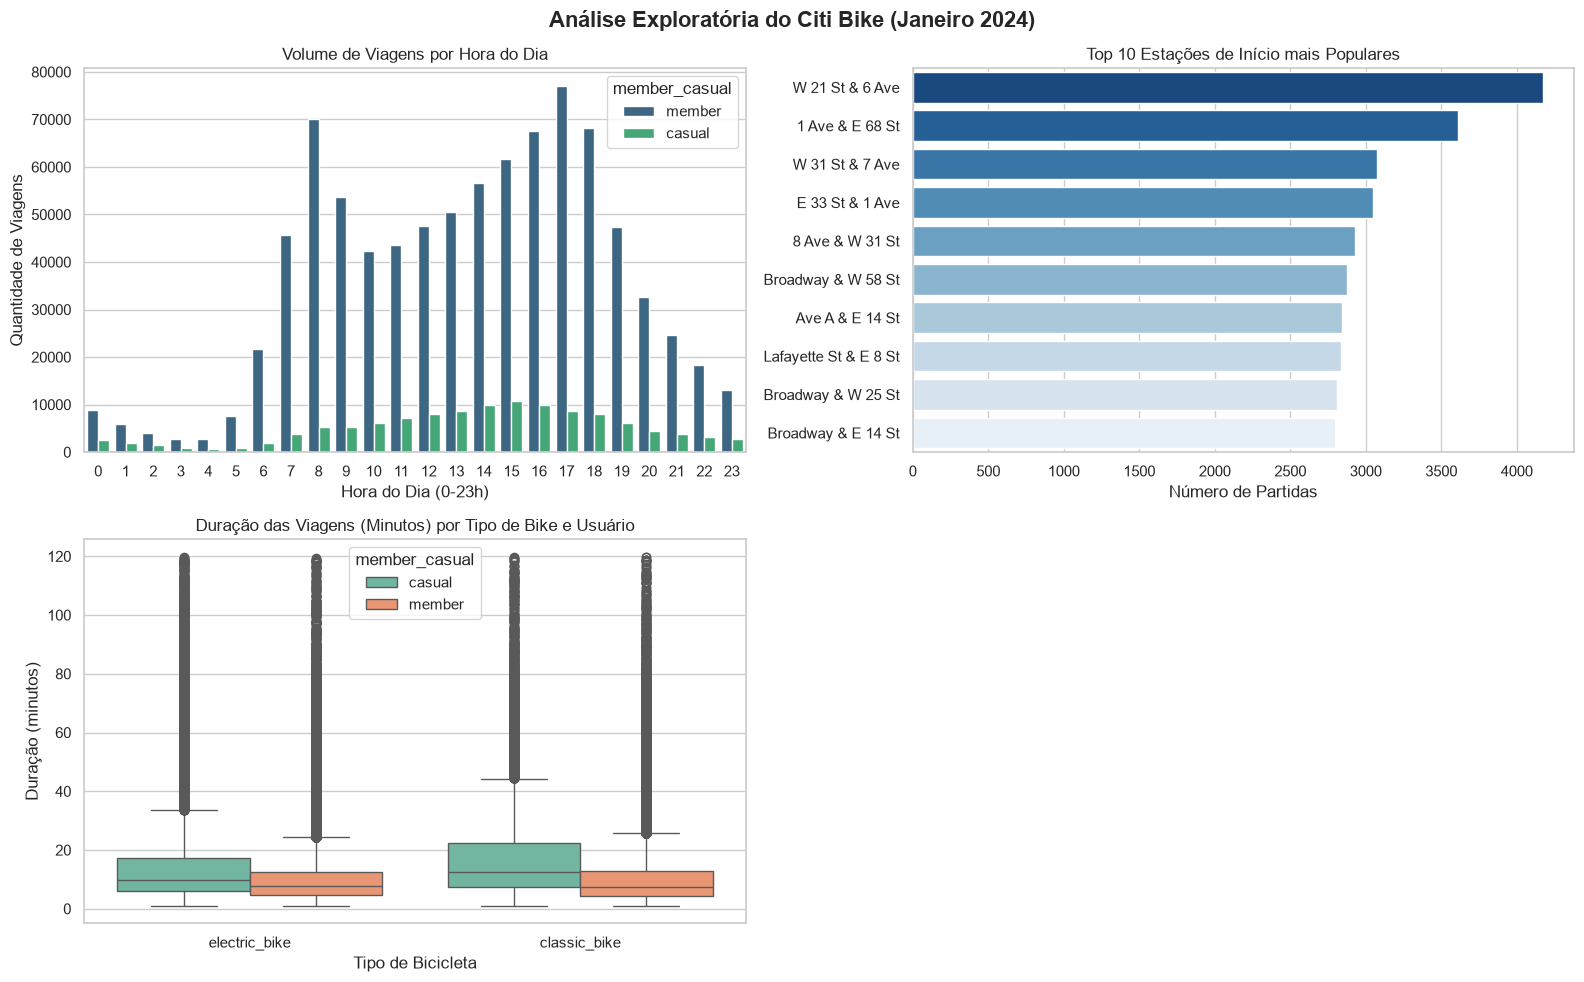

In [21]:


# Configuração de estilo dos gráficos
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (15, 10)

# 2. Engenharia de Features rápida
df['hour'] = df['started_at'].dt.hour
df['duration_min'] = (df['ended_at'] - df['started_at']).dt.total_seconds() / 60

# Filtra outliers de duração (viagens acima de 2 horas ou negativas/zero)
df_clean = df[(df['duration_min'] > 1) & (df['duration_min'] < 120)]

# 3. Criação da figura com 3 subplots
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Análise Exploratória do Citi Bike (Janeiro 2024)', fontsize=16, fontweight='bold')

# Gráfico 1: Volume por Hora do Dia
sns.countplot(ax=axes[0, 0], data=df, x='hour', hue='member_casual', palette='viridis')
axes[0, 0].set_title('Volume de Viagens por Hora do Dia')
axes[0, 0].set_xlabel('Hora do Dia (0-23h)')
axes[0, 0].set_ylabel('Quantidade de Viagens')

# Gráfico 2: Top 10 Estações de Origem
top_stations = df['start_station_name'].value_counts().head(10).reset_index()
top_stations.columns = ['station', 'count']
# Gráfico 2: Top 10 Estações de Origem (Corrigido para Seaborn >= 0.14)
sns.barplot(
    ax=axes[0, 1],
    data=top_stations,
    y='station',
    x='count',
    hue='station',
    palette='Blues_r',
    legend=False
)
axes[0, 1].set_title('Top 10 Estações de Início mais Populares')
axes[0, 1].set_xlabel('Número de Partidas')
axes[0, 1].set_ylabel('')

# Gráfico 3: Distribuição da Duração das Viagens
sns.boxplot(ax=axes[1, 0], data=df_clean, x='rideable_type', y='duration_min', hue='member_casual', palette='Set2')
axes[1, 0].set_title('Duração das Viagens (Minutos) por Tipo de Bike e Usuário')
axes[1, 0].set_xlabel('Tipo de Bicicleta')
axes[1, 0].set_ylabel('Duração (minutos)')

# Oculta o 4º subplot vago
fig.delaxes(axes[1, 1])

plt.tight_layout()
plt.show()

In [22]:

# Configuração de estilo
sns.set_theme(style="whitegrid")

# 1. Cálculo da duração em minutos
df['duration_min'] = (df['ended_at'] - df['started_at']).dt.total_seconds() / 60

# 2. Limpeza de dados (remoção de durações nulas/negativas e travamentos acima de 2h)
df_clean = df[(df['duration_min'] > 0) & (df['duration_min'] <= 120)].copy()

# 3. Estatísticas Descritivas Globais
stats_globais = df_clean['duration_min'].describe(
    percentiles=[0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

# 4. Estatísticas Descritivas por Categoria de Usuário
stats_por_usuario = df_clean.groupby('member_casual')['duration_min'].agg(
    ['count', 'mean', 'std', 'min', lambda x: x.quantile(0.25), 'median', lambda x: x.quantile(0.75), 'max']
).rename(columns={'<lambda_0>': '25%', '<lambda_1>': '75%'})

print("--- Estatísticas Globais ---")
print(stats_globais)
print("\n--- Estatísticas por Tipo de Usuário ---")
print(stats_por_usuario)

--- Estatísticas Globais ---
count    995100.000000
mean         10.671273
std           9.513046
min           1.001100
5%            2.223867
25%           4.727467
50%           7.886483
75%          13.311312
90%          21.497625
95%          28.415079
99%          46.769887
max         119.831650
Name: duration_min, dtype: float64

--- Estatísticas por Tipo de Usuário ---
                count       mean        std       min       25%     median  \
member_casual                                                                
casual         121555  15.001459  14.049387  1.009817  6.370492  10.521750   
member         873545  10.068721   8.523644  1.001100  4.555417   7.585567   

                     75%         max  
member_casual                         
casual         18.406492  119.793867  
member         12.705033  119.831650  


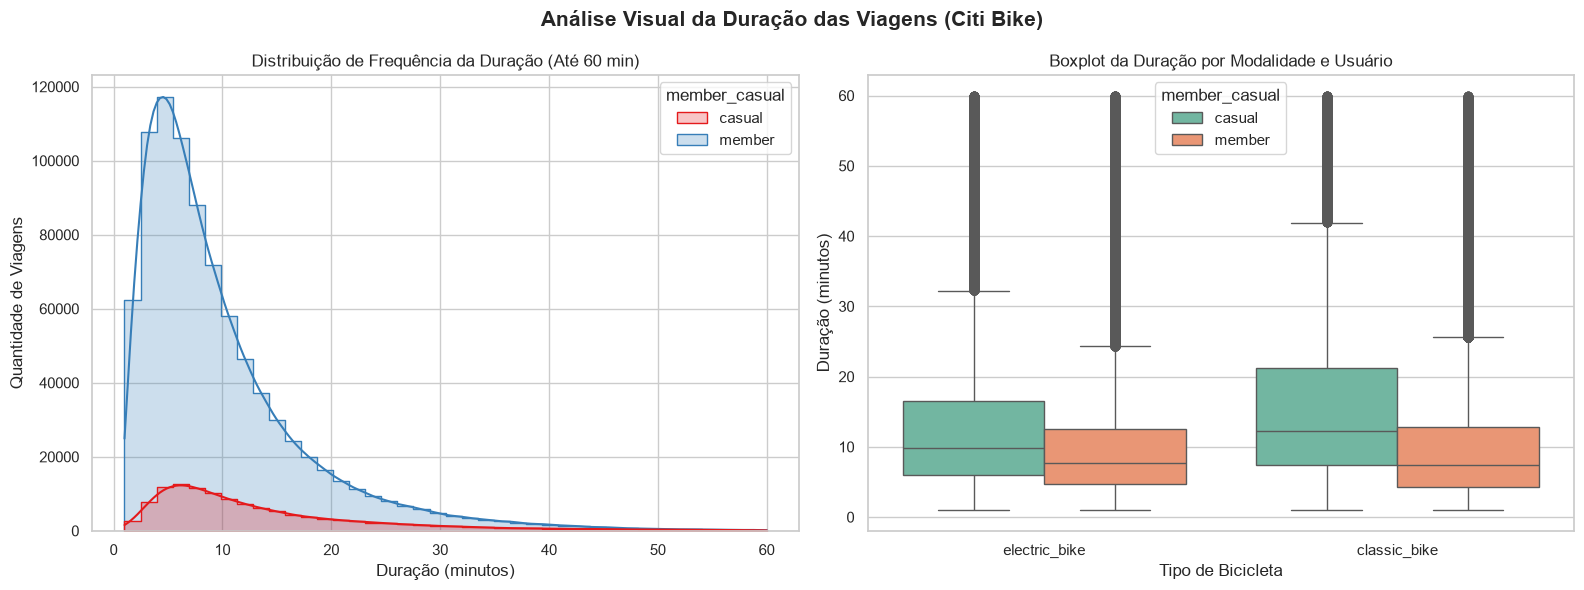

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Análise Visual da Duração das Viagens (Citi Bike)', fontsize=15, fontweight='bold')

# Gráfico 1: Histograma + KDE da Distribuição de Duração
sns.histplot(
    ax=axes[0],
    data=df_clean[df_clean['duration_min'] <= 60],
    x='duration_min',
    bins=40,
    kde=True,
    hue='member_casual',
    palette='Set1',
    element='step'
)
axes[0].set_title('Distribuição de Frequência da Duração (Até 60 min)')
axes[0].set_xlabel('Duração (minutos)')
axes[0].set_ylabel('Quantidade de Viagens')

# Gráfico 2: Boxplot por Tipo de Bicicleta e Categoria de Usuário
sns.boxplot(
    ax=axes[1],
    data=df_clean[df_clean['duration_min'] <= 60],
    x='rideable_type',
    y='duration_min',
    hue='member_casual',
    palette='Set2'
)
axes[1].set_title('Boxplot da Duração por Modalidade e Usuário')
axes[1].set_xlabel('Tipo de Bicicleta')
axes[1].set_ylabel('Duração (minutos)')

plt.tight_layout()
plt.show()

ride_id                         F373EDD45C4A8927
rideable_type                      electric_bike
started_at            2024-01-08 19:34:07.217000
ended_at              2024-01-09 20:33:13.307000
duration_min                           1499.1015
member_casual                             casual
start_station_name             10 Ave & W 207 St
end_station_name      W 230 St & Marble Hill Ave


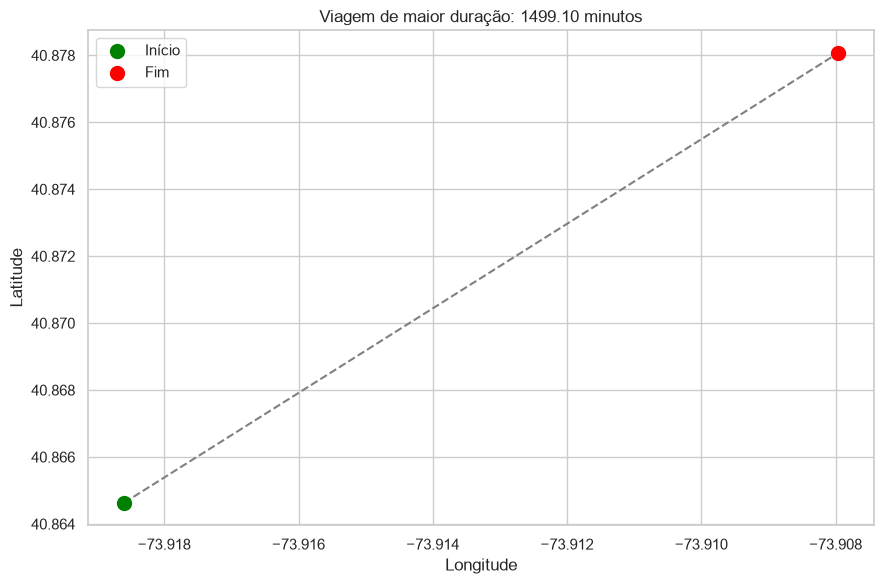

In [24]:

# 1. Calcula a duração em minutos
df['duration_min'] = (df['ended_at'] - df['started_at']).dt.total_seconds() / 60

# 2. Localiza a linha com a maior duração (desconsiderando erros/outliers se desejar)
viagem_longa = df.loc[df['duration_min'].idxmax()]

# 3. Exibe as informações da viagem
colunas = [
    'ride_id', 'rideable_type', 'started_at', 'ended_at', 'duration_min',
    'member_casual', 'start_station_name', 'end_station_name'
]
print(viagem_longa[colunas].to_string())

# 4. Plota o trajeto entre as estações de início e fim
if viagem_longa[['start_lat', 'start_lng', 'end_lat', 'end_lng']].notna().all():
    fig, ax = plt.subplots(figsize=(9, 6))

    ax.plot(
        [viagem_longa['start_lng'], viagem_longa['end_lng']],
        [viagem_longa['start_lat'], viagem_longa['end_lat']],
        color='gray', linestyle='--', zorder=1
    )
    ax.scatter(viagem_longa['start_lng'], viagem_longa['start_lat'],
               color='green', s=100, label='Início', zorder=2)
    ax.scatter(viagem_longa['end_lng'], viagem_longa['end_lat'],
               color='red', s=100, label='Fim', zorder=2)

    ax.set_title(f"Viagem de maior duração: {viagem_longa['duration_min']:.2f} minutos")
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print("Não há coordenadas disponíveis para plotar o trajeto.")


In [25]:


# 2. Pega a viagem de MAIOR DURAÇÃO absoluta do dataset (sem filtros)
maior_duracao = df.loc[df['duration_min'].idxmax()]

print("--- Viagem de MAIOR DURAÇÃO ---")
print(f"Duração: {maior_duracao['duration_min'] / 60:.1f} horas ({(maior_duracao['duration_min'] / 1440):.1f} dias)")
print(f"Saída: {maior_duracao['started_at']} em {maior_duracao['start_station_name']}")
print(f"Chegada: {maior_duracao['ended_at']} em {maior_duracao['end_station_name']}")

# 3. Plota no mapa de onde a pessoa tirou a bike e onde ela foi devolvida dias depois
centro_lat = (maior_duracao['start_lat'] + maior_duracao['end_lat']) / 2
centro_lng = (maior_duracao['start_lng'] + maior_duracao['end_lng']) / 2

mapa = folium.Map(location=[centro_lat, centro_lng], zoom_start=12, tiles="OpenStreetMap")

folium.Marker(
    location=[maior_duracao['start_lat'], maior_duracao['start_lng']],
    popup=f"<b>Início:</b> {maior_duracao['start_station_name']}",
    icon=folium.Icon(color="green", icon="play")
).add_to(mapa)

folium.Marker(
    location=[maior_duracao['end_lat'], maior_duracao['end_lng']],
    popup=f"<b>Fim:</b> {maior_duracao['end_station_name']}",
    icon=folium.Icon(color="red", icon="stop")
).add_to(mapa)

folium.PolyLine(
    locations=[
        [maior_duracao['start_lat'], maior_duracao['start_lng']],
        [maior_duracao['end_lat'], maior_duracao['end_lng']]
    ],
    color="purple", weight=4, dash_array="10",
    tooltip=f"Viagem demorou {maior_duracao['duration_min'] / 60:.1f} horas"
).add_to(mapa)

mapa

--- Viagem de MAIOR DURAÇÃO ---
Duração: 25.0 horas (1.0 dias)
Saída: 2024-01-08 19:34:07.217000 em 10 Ave & W 207 St
Chegada: 2024-01-09 20:33:13.307000 em W 230 St & Marble Hill Ave


In [26]:
df.columns

Index(['ride_id', 'rideable_type', 'started_at', 'ended_at',
       'start_station_name', 'start_station_id', 'end_station_name',
       'end_station_id', 'start_lat', 'start_lng', 'end_lat', 'end_lng',
       'member_casual', 'hour', 'duration_min'],
      dtype='str')

In [27]:


def calcular_distancia_haversine(lat1, lon1, lat2, lon2):
    """
    Calcula a distância em quilômetros entre dois pontos geográficos.
    """
    # Raio médio da Terra em quilômetros
    R = 6371.0

    # Converte as coordenadas de graus para radianos
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])

    # Diferença entre as coordenadas
    dlat = lat2 - lat1
    dlon = lon2 - lon1

    # Fórmula de Haversine
    a = np.sin(dlat / 2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0)**2
    c = 2 * np.arcsin(np.sqrt(a))
    
    return R * c

# Cria a nova coluna 'distancia' no DataFrame (em Km)
df['distancia'] = calcular_distancia_haversine(
    df['start_lat'], 
    df['start_lng'], 
    df['end_lat'], 
    df['end_lng']
)

# Visualiza as primeiras linhas para confirmar
print(df[['start_station_name', 'end_station_name', 'duration_min', 'distancia']].head())

            start_station_name           end_station_name  duration_min  \
0                 3 St & 3 Ave      Carroll St & Smith St      4.001483   
1  Franklin Ave & St Marks Ave    Bedford Ave & Bergen St     16.545767   
2           W 67 St & Broadway  Central Park W & W 103 St     35.800700   
3  Central Park West & W 68 St             E 5 St & Ave C     25.179133   
4           W 67 St & Broadway            Ave A & E 14 St     44.388583   

   distancia  
0   0.853581  
1   0.280447  
2   2.888093  
3   5.608708  
4   4.964338  


In [29]:


# 1. Selecionar features relevantes (removendo nulos)
features = ['rideable_type', 'distancia', 'duration_min']
df_cluster = df_clean.dropna(subset=features).copy()

# Opcional: Pegar uma amostra de 50.000 viagens para rodar o agrupamento rápido
df_sample = df_cluster.sample(n=50000, random_state=42)

# 2. Padronização dos dados (CRÍTICO para K-Means)
# Como latitude e duração estão em escalas totalmente diferentes, precisamos padronizar
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_sample[features])

# 3. Treinar o modelo K-Means (vamos começar buscando 4 grupos/perfis)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df_sample['cluster'] = kmeans.fit_predict(X_scaled)
df_sample['cluster'] = df_sample['cluster'].astype(str) # Converter para string para o Seaborn tratar como categoria

# 4. Analisar os centroides (a média de cada grupo) para entender quem são
centroides = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=features)
centroides.index.name = 'Cluster'
print("--- Perfil Médio de Cada Grupo (Centroides) ---")
print(centroides.round(2))
print("\n")

# 5. Visualização Espacial dos Grupos (Lat x Lng)
plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=df_sample, 
    x='start_lng', 
    y='start_lat', 
    hue='cluster', 
    palette='Set1', 
    s=15, 
    alpha=0.6
)
plt.title('Distribuição Geográfica dos Grupos de Viagem (Clusters)', fontsize=14)
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.legend(title='Grupo (Cluster)')
plt.grid(True)
plt.show()

KeyError: ['distancia']